
# Gasturbine – Vorhersage von Stickoxidemissionen (NOx)

## Beschreibung des Datensatzes

Der Datensatz enthält **36.733 reale Betriebsdatensätze** einer Gasturbine aus einem Kraftwerk in der Türkei. Die Messwerte wurden zwischen **2011 und 2015** aufgezeichnet und liegen als stündlich aggregierte Sensordaten vor.

**Ziel:** Mithilfe eines neuronalen Netzes in PyTorch sollen die **Stickoxidemissionen (NOx)** der Gasturbine anhand verschiedener Betriebsparameter vorhergesagt werden.

## Messgrößen und Kennwerte

| Kürzel | Messgröße | Einheit | Min. | Max. | Mittelwert |
|:---|:---|:---:|---:|---:|---:|
| AT | Umgebungstemperatur | °C | −6,23 | 37,10 | 17,71 |
| AP | Umgebungsdruck | mbar | 985,85 | 1036,56 | 1013,07 |
| AH | Umgebungsfeuchte | % | 24,08 | 100,20 | 77,87 |
| AFDP | Differenzdruck am Luftfilter | mbar | 2,09 | 7,61 | 3,93 |
| GTEP | Abgasdruck der Gasturbine | mbar | 17,70 | 40,72 | 25,56 |
| TIT | Turbineneintrittstemperatur | °C | 1000,85 | 1100,89 | 1081,43 |
| TAT | Temperatur nach der Turbine | °C | 511,04 | 550,61 | 546,16 |
| CDP | Verdichteraustrittsdruck | mbar | 9,85 | 15,16 | 12,06 |
| TEY | Energieertrag der Turbine | MWh | 100,02 | 179,50 | 133,51 |
| CO | Kohlenmonoxid | mg/m³ | 0,00 | 44,10 | 2,37 |
| NOx | Stickoxide | mg/m³ | 25,90 | 119,91 | 65,29 |

Die in diesem Modell verwendeten Eingangsgrößen sind AT, GTEP, TIT, TAT und CDP. NOx ist die Zielgröße; die übrigen Messgrößen dienen hier der Beschreibung des Datensatzes.

## Zielgröße (Target)

| Kürzel | Messgröße | Einheit |
|:---|:---|:---:|
| **NOX** | Stickoxidemissionen | mg/m³ |

## Warum ist dieser Datensatz interessant?

- **Reale Maschinendaten:** Die Messwerte stammen aus dem Betrieb einer industriellen Gasturbine.
- **Nichtlineare Zusammenhänge:** Die NOx-Emissionen hängen unter anderem von Verbrennungstemperaturen und Betriebsbedingungen ab.
- **Mehrere Eingangsgrößen:** Der Einfluss verschiedener Sensorwerte auf die Vorhersage lässt sich untersuchen.
- **Modellvergleich:** Lineare Regression und neuronale Netze können hinsichtlich ihrer Vorhersagegenauigkeit verglichen werden.
- **Feature-Auswahl:** Durch gezieltes Entfernen einzelner Eingangsgrößen lässt sich deren Bedeutung untersuchen.

## Datenquelle

[UCI Machine Learning Repository – Gas Turbine CO and NOx Emission Data Set](https://archive.ics.uci.edu/dataset/551/gas+turbine+co+and+nox+emission+data+set)


# Datensatz runterladen

In [1]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
ds = fetch_ucirepo(id=551)

In [2]:
ds.metadata

{'uci_id': 551,
 'name': 'Gas Turbine CO and NOx Emission Data Set',
 'repository_url': 'https://archive.ics.uci.edu/dataset/551/gas+turbine+co+and+nox+emission+data+set',
 'data_url': 'https://archive.ics.uci.edu/static/public/551/data.csv',
 'abstract': 'The dataset contains 36733 instances of 11 sensor measures aggregated over one hour, from a gas turbine located in Turkey for the purpose of studying flue gas emissions, namely CO and NOx.',
 'area': 'Computer Science',
 'tasks': ['Regression', 'Clustering'],
 'characteristics': ['Multivariate'],
 'num_instances': 36733,
 'num_features': 12,
 'feature_types': ['Real'],
 'demographics': [],
 'target_col': None,
 'index_col': None,
 'has_missing_values': 'no',
 'missing_values_symbol': None,
 'year_of_dataset_creation': 2019,
 'last_updated': 'Fri Mar 29 2024',
 'dataset_doi': '10.24432/C5WC95',
 'creators': [],
 'intro_paper': None,
 'additional_info': {'summary': "The dataset contains 36733 instances of 11 sensor measures aggregated 

In [21]:
type(ds.metadata)

ucimlrepo.dotdict.dotdict

In [24]:
print( ds.metadata["additional_info"]["variable_info"] )

The explanations of sensor measurements and their brief statistics are given below. 

Variable (Abbr.) Unit Min Max Mean
Ambient temperature (AT) C â€“6.23 37.10 17.71
Ambient pressure (AP) mbar 985.85 1036.56 1013.07
Ambient humidity (AH) (%) 24.08 100.20 77.87
Air filter difference pressure (AFDP) mbar 2.09 7.61 3.93
Gas turbine exhaust pressure (GTEP) mbar 17.70 40.72 25.56
Turbine inlet temperature (TIT) C 1000.85 1100.89 1081.43
Turbine after temperature (TAT) C 511.04 550.61 546.16
Compressor discharge pressure (CDP) mbar 9.85 15.16 12.06
Turbine energy yield (TEY) MWH 100.02 179.50 133.51
Carbon monoxide (CO) mg/m3 0.00 44.10 2.37
Nitrogen oxides (NOx) mg/m3 25.90 119.91 65.29


In [3]:
ds.variables

,name,role,type,demographic,description,units,missing_values
0,year,Feature,Integer,None,None,None,no
1,AT,Feature,Continuous,None,None,None,no
2,AP,Feature,Continuous,None,None,None,no
3,AH,Feature,Continuous,None,None,None,no
4,AFDP,Feature,Continuous,None,None,None,no
5,GTEP,Feature,Continuous,None,None,None,no
6,TIT,Feature,Continuous,None,None,None,no
7,TAT,Feature,Continuous,None,None,None,no
8,TEY,Feature,Continuous,None,None,None,no
9,CDP,Feature,Continuous,None,None,None,no


In [4]:
ds.data.features

,year,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,2011,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,2011,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,2011,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,2011,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,2011,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028
...,...,...,...,...,...,...,...,...,...,...,...,...
36728,2015,3.6268,1028.5,93.200,3.1661,19.087,1037.0,541.59,109.08,10.411,10.99300,89.172
36729,2015,4.1674,1028.6,94.036,3.1923,19.016,1037.6,542.28,108.79,10.344,11.14400,88.849
36730,2015,5.4820,1028.5,95.219,3.3128,18.857,1038.0,543.48,107.81,10.462,11.41400,96.147
36731,2015,5.8837,1028.7,94.200,3.9831,23.563,1076.9,550.11,131.41,11.771,3.31340,64.738


# Correlation Analysis

In [6]:
ds.keys()

dict_keys(['data', 'metadata', 'variables'])

In [7]:
ds.data.keys()

dict_keys(['ids', 'features', 'targets', 'original', 'headers'])

In [9]:
df = ds.data.original
df

,year,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,2011,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,2011,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,2011,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,2011,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,2011,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028
...,...,...,...,...,...,...,...,...,...,...,...,...
36728,2015,3.6268,1028.5,93.200,3.1661,19.087,1037.0,541.59,109.08,10.411,10.99300,89.172
36729,2015,4.1674,1028.6,94.036,3.1923,19.016,1037.6,542.28,108.79,10.344,11.14400,88.849
36730,2015,5.4820,1028.5,95.219,3.3128,18.857,1038.0,543.48,107.81,10.462,11.41400,96.147
36731,2015,5.8837,1028.7,94.200,3.9831,23.563,1076.9,550.11,131.41,11.771,3.31340,64.738


In [10]:
df.to_csv("gas_turbine.csv", index=False)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36733 entries, 0 to 36732
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   year    36733 non-null  int64  
 1   AT      36733 non-null  float64
 2   AP      36733 non-null  float64
 3   AH      36733 non-null  float64
 4   AFDP    36733 non-null  float64
 5   GTEP    36733 non-null  float64
 6   TIT     36733 non-null  float64
 7   TAT     36733 non-null  float64
 8   TEY     36733 non-null  float64
 9   CDP     36733 non-null  float64
 10  CO      36733 non-null  float64
 11  NOX     36733 non-null  float64
dtypes: float64(11), int64(1)
memory usage: 3.4 MB


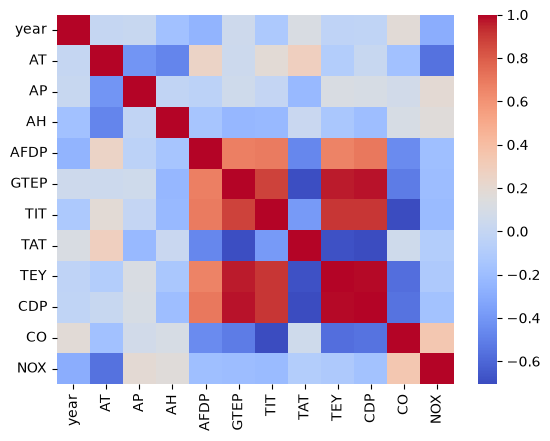

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.heatmap(df.corr(), cmap="coolwarm")
plt.show()

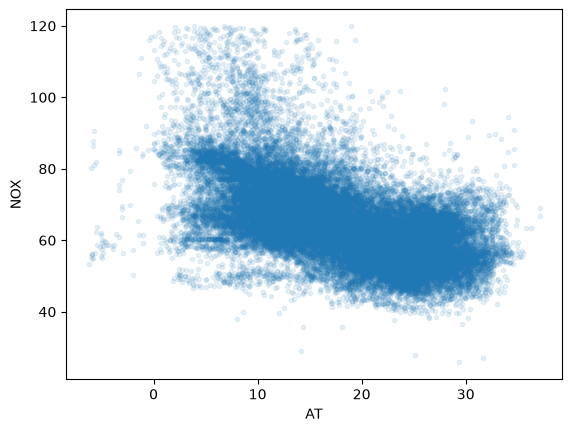

In [19]:
plt.scatter( df["AT"], df["NOX"], marker=".", alpha=0.1 )
plt.xlabel("AT")
plt.ylabel("NOX")
plt.show()